# Sector Means of the Main Relevance Score Relative to the Sample Mean

| Item | Description |
|---|---|
| Goal | One figure for the main relevance measure, the cosine similarity between a firm-level summary of 10-K Item 1s and the policy summary of legislator statements on consumer data privacy legislation: one horizontal bar per NAICS two-digit sector showing the sector mean of the firm score minus the sample mean over all firms, so that zero is the sample mean, sectors sorted from the highest to the lowest, with nested 90, 95, and 99 percent confidence intervals of the sector mean. The one-measure version of Figure 9 of the archived T3.9.3. |
| Input | `output/T3.8.3/firm_relevance_scores_wide.csv` (T3.8.3); the CRSP-Compustat link file `crsp_compustat_link.dta` in the source data folder for each firm's Compustat NAICS code. |
| Output | `output/T3.9.3/sector_means.csv`: one row per sector with the number of firms, the sector mean, its standard deviation, the difference from the sample mean, and the half-widths of the three intervals. `output/T3.9.3/fig_sector_mean_minus_sample_mean_policy_summary_firm_summary_cosine_naics2.{png,svg,pdf}`. |
| Unit | A NAICS two-digit sector; the firm is the unit the sector mean is taken over. Firms are those of the sample set by `SAMPLE`: all years (every fiscal year a firm filed, 1999 to 2025; 1,058 firms) or the three years (fiscal 2010, 2015, 2020; 841 firms). |
| Sectors | Compustat's NAICS code for the firm, cut to two digits, as in T3.9.1 and T3.9.2: 31 to 33 merged into manufacturing, 44 to 45 into retail trade, 48 to 49 into transportation and warehousing. Sectors with fewer than `MIN_FIRMS` firms are left out of the figure and named in the Notes. |
| Measure | `MEASURE_ID`, T3.8.3's `summaries \| policy_summary \| firm_summary`, as in T3.9.1 and T3.9.2. |
| Intervals | Two-sided normal confidence intervals of the sector mean from the standard deviation of the firm scores within the sector, nested and drawn without caps: 90 percent (1.645 standard errors, the thickest line) inside 95 percent (1.960, medium) inside 99 percent (2.576, the thinnest and longest line). |
| Wording | Every title, axis title, and tick label spells out what is measured, as in T3.9.1 and T3.9.2: each tick label carries the sector name, its NAICS codes, and its number of firms. Axis titles and tick labels are in title case at the user's request; the figure title follows S3 title case. |
| Style | S3: 9 by 6 inches, Times, 0.5 cm margins, no text inside the plot, GREY bars with BLUE intervals so that the intervals stand out, a solid BLACK zero line, no legend (one series; the intervals are explained in the Notes), title and notes in Markdown below. |

See `README.md` in the TEMP folder for the surrounding steps, `T3.8.3` for the measure, the archived `T3.9.3 - Figure - Most and Least Relevant Industries` (in `archive`) for the same figure on every measure, and `T3.9.1` and `T3.9.2` for the distribution and the firms on this measure.


## Step 1. Import packages


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display


## Step 2. Define file locations, the measure, the sectors, and the wording

The wording is built from the same two phrases as T3.9.1 and T3.9.2. The sector names of the archived T3.9.3 are kept and shown in title case with their NAICS codes.


In [2]:
PROJECT_FOLDER = Path("/project2/njia_1089/acroh/projects/LLM-Text-Analysis-and-Synthesis")
SOURCE_DATA_FOLDER = Path("/project2/mmiric_1435/acroh/llm_method/data")
NOTEBOOK_SUBFOLDER = Path("T3 - Topic Relevance and Corporate Disclosure/TEMP")
NOTEBOOK_NAME = "T3.9.3"  # the identifier names this notebook's output folder
TEMP_OUTPUT = PROJECT_FOLDER / NOTEBOOK_SUBFOLDER / "output"
OUTPUT_FOLDER = TEMP_OUTPUT / NOTEBOOK_NAME
SCORES_FILE = TEMP_OUTPUT / "T3.8.3/firm_relevance_scores_wide.csv"
LINK_FILE = SOURCE_DATA_FOLDER / "interim/repo_data/raw/01_firm_id/crsp_compustat_link.dta"

SAMPLE = "all_years"  # the main sample; "three_years" for the three-year figures
SAMPLE_WORDS = {"three_years": "the three-year sample (fiscal years 2010, 2015, and 2020)", "all_years": "the all-years sample (every fiscal year a firm filed, 1999 to 2025)"}
MEASURE_ID = "summaries | policy_summary | firm_summary"
MIN_FIRMS = 5  # a sector with fewer firms is left out of the figure
Z_VALUES = {90: 1.645, 95: 1.960, 99: 2.576}  # two-sided normal critical values; the wider the interval, the thinner its line
NAICS_SECTORS = {  # two-digit code -> sector name; codes that share a sector map to the same name
    "11": "Agriculture, forestry, fishing and hunting", "21": "Mining, quarrying, and oil and gas extraction", "22": "Utilities", "23": "Construction",
    "31": "Manufacturing", "32": "Manufacturing", "33": "Manufacturing", "42": "Wholesale trade", "44": "Retail trade", "45": "Retail trade",
    "48": "Transportation and warehousing", "49": "Transportation and warehousing", "51": "Information", "52": "Finance and insurance",
    "53": "Real estate and rental and leasing", "54": "Professional, scientific, and technical services", "55": "Management of companies and enterprises",
    "56": "Administrative and support and waste management", "61": "Educational services", "62": "Health care and social assistance",
    "71": "Arts, entertainment, and recreation", "72": "Accommodation and food services", "81": "Other services", "92": "Public administration",
    "99": "Unclassified",
}
LOWERCASE_WORDS = {"a", "an", "the", "and", "or", "but", "of", "in", "on", "at", "to", "for", "by"}  # kept lowercase in title case
SECTOR_TITLES = {name: " ".join(word if word in LOWERCASE_WORDS and i > 0 else word[0].upper() + word[1:] for i, word in enumerate(name.split(" ")))
                 for name in set(NAICS_SECTORS.values())}
SECTOR_CODES = {}  # sector name -> "51" or "31 to 33"
for code, name in NAICS_SECTORS.items():
    codes = sorted(c for c, n in NAICS_SECTORS.items() if n == name)
    SECTOR_CODES[name] = codes[0] if len(codes) == 1 else f"{codes[0]} to {codes[-1]}"

# Wording. The two texts compared, in title case, then the titles built from them.
FIRM_SUMMARY_TITLE = "a Firm-Level Summary of 10-K Item 1s"
POLICY_SUMMARY_TITLE = "the Policy Summary of Legislator Statements on Consumer Data Privacy Legislation"
SCORE_TITLE = f"Cosine Similarity Between {FIRM_SUMMARY_TITLE} and {POLICY_SUMMARY_TITLE}"
FIGURE_TITLE = f"Sector Mean Minus Sample Mean of {SCORE_TITLE}, by NAICS Two-Digit Sector"
X_TITLE = ("Sector Mean Minus Sample Mean of Cosine Similarity Between\na Firm-Level Summary of 10-K Item 1s and the Policy Summary\n"
           "of Legislator Statements on Consumer Data Privacy Legislation")  # the figure title's words on three lines, each narrower than the plot area, which sits right of the tick labels
Y_TITLE = "NAICS Two-Digit Sector (NAICS Codes, Number of Firms)"
SCORE_WORDS = ("the cosine similarity between two embeddings: the firm-level summary, one paragraph written by the language model that condenses the firm's "
               "yearly summaries of its 10-K Item 1 (Business) sections over its fiscal years in the sample, and the policy summary, one text written by the "
               "language model that condenses the legislator statements on Topic 68, consumer data privacy legislation, extracted from congressional hearings. "
               "A higher score means that the firm's business description is closer to the policy summary")
FIGURE_NAME = "fig_sector_mean_minus_sample_mean_policy_summary_firm_summary_cosine_naics2"
SOURCE = "10-K Item 1 sections from SEC EDGAR; congressional hearing statements from GovInfo; NAICS codes from Compustat through the CRSP-Compustat link; authors' calculations"
OUTPUT_FOLDER.mkdir(parents=True, exist_ok=True)
print(f"Outputs: {OUTPUT_FOLDER}")


Outputs: /project2/njia_1089/acroh/projects/LLM-Text-Analysis-and-Synthesis/T3 - Topic Relevance and Corporate Disclosure/TEMP/output/T3.9.3


## Step 3. Figure style

The S3 settings: canvas, font, colors, horizontal background lines only. GREY bars, BLUE intervals, a BLACK zero line; the tick labels are set at a smaller size because each carries two lines.


In [3]:
RED = "#B31942"
BLUE = "#0A3161"
MIDNIGHT_BLUE = "#004953"
GREY = "#A6A6A8"
BLACK = "#101820"
FIGURE_WIDTH = 9
FIGURE_HEIGHT = 6
MARGIN_INCHES = 0.5 / 2.54
ZERO_LINE_WIDTH = 0.8 / 3  # S3 zero line
BAR_HEIGHT = 0.7
INTERVAL_WIDTHS = {90: 3.2, 95: 1.8, 99: 0.8}  # line widths of the nested intervals, thickest for the narrowest
TICK_LABEL_SIZE = 9
EXPORT_DPI = 300

plt.rcParams["font.family"] = "serif"
plt.rcParams["font.serif"] = ["Times New Roman", "Times", "Liberation Serif", "DejaVu Serif"]
plt.rcParams["font.size"] = 11
plt.rcParams["figure.figsize"] = (FIGURE_WIDTH, FIGURE_HEIGHT)
plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["axes.facecolor"] = "white"
plt.rcParams["axes.unicode_minus"] = True
plt.rcParams["axes.grid"] = True
plt.rcParams["axes.grid.axis"] = "y"
plt.rcParams["axes.axisbelow"] = True
plt.rcParams["grid.color"] = GREY
plt.rcParams["grid.linewidth"] = 0.5
plt.rcParams["text.color"] = BLACK
plt.rcParams["axes.labelcolor"] = BLACK
plt.rcParams["axes.edgecolor"] = BLACK
plt.rcParams["xtick.color"] = BLACK
plt.rcParams["ytick.color"] = BLACK


## Step 4. Load the scores and attach a NAICS sector to every firm

The wide table of T3.8.3, the chosen sample only; the sector comes from the link file exactly as in T3.9.1 and T3.9.2. The measure column must be present and complete, and every firm must get a sector.


In [4]:
wide = pd.read_csv(SCORES_FILE, dtype={"gvkey": str})
wide = wide.loc[wide["sample"].eq(SAMPLE)].reset_index(drop=True)
assert MEASURE_ID in wide.columns, MEASURE_ID
assert wide[MEASURE_ID].notna().all(), f"{int(wide[MEASURE_ID].isna().sum())} firms without a score"

link = pd.read_stata(LINK_FILE, columns=["GVKEY", "naics"])
link["gvkey"] = link["GVKEY"].astype(str).str.zfill(6)
link["naics"] = link["naics"].astype(str).str.strip().replace({"": None, "nan": None})
link = link.dropna(subset=["naics"])
assert link.groupby("gvkey")["naics"].nunique().le(1).all(), "a gvkey with two NAICS codes"
naics = link.drop_duplicates("gvkey").set_index("gvkey")["naics"]
wide["naics"] = wide["gvkey"].map(naics)
assert wide["naics"].notna().all(), f"{int(wide['naics'].isna().sum())} firms without a NAICS code"
wide["naics2"] = wide["naics"].str[:2]
assert wide["naics2"].isin(NAICS_SECTORS).all(), sorted(set(wide["naics2"]) - set(NAICS_SECTORS))
wide["sector"] = wide["naics2"].map(NAICS_SECTORS)
sector_sizes = wide.groupby("sector").size().sort_values(ascending=False)
print(f"Firms in the {SAMPLE} sample: {len(wide):,}; sectors: {len(sector_sizes)}; sectors with fewer than {MIN_FIRMS} firms (left out of the figure): "
      f"{', '.join(f'{s} ({n})' for s, n in sector_sizes[sector_sizes < MIN_FIRMS].items()) or 'none'}")
display(sector_sizes.rename("firms").to_frame().T)


Firms in the all_years sample: 1,058; sectors: 19; sectors with fewer than 5 firms (left out of the figure): Unclassified (4), Other services (3), Educational services (3), Agriculture, forestry, fishing and hunting (3)


sector,Manufacturing,Finance and insurance,Information,Retail trade,Utilities,"Mining, quarrying, and oil and gas extraction",Real estate and rental and leasing,"Professional, scientific, and technical services",Transportation and warehousing,Wholesale trade,Accommodation and food services,Administrative and support and waste management,Health care and social assistance,Construction,"Arts, entertainment, and recreation",Unclassified,Other services,Educational services,"Agriculture, forestry, fishing and hunting"
firms,420,149,113,59,58,53,47,38,27,21,17,14,13,11,5,4,3,3,3


## Step 5. Compute the sector means, the sample mean, and the intervals

The mean over all sample firms; within each sector the number of firms, the mean, and the standard deviation of the firm scores; the sector mean minus the sample mean, which is what the bars show; and the half-widths of the 90, 95, and 99 percent confidence intervals of the sector mean, the critical value times the standard deviation over the square root of the number of firms. Saved as one table sorted from the highest to the lowest sector mean.


In [5]:
sample_mean = float(wide[MEASURE_ID].mean())
sectors = wide.groupby("sector")[MEASURE_ID].agg(n_firms="size", sector_mean="mean", sector_sd="std").reset_index()
sectors["sample_mean"] = sample_mean
sectors["difference_from_sample_mean"] = sectors["sector_mean"] - sample_mean
sectors["standard_error"] = sectors["sector_sd"] / np.sqrt(sectors["n_firms"])
for level, z in Z_VALUES.items():
    sectors[f"ci{level}_half_width"] = z * sectors["standard_error"]
sectors["naics_codes"] = sectors["sector"].map(SECTOR_CODES)
sectors = sectors.sort_values("sector_mean", ascending=False).reset_index(drop=True)
sectors.to_csv(OUTPUT_FOLDER / "sector_means.csv", index=False, float_format="%.6f")
print(f"Saved: {OUTPUT_FOLDER / 'sector_means.csv'} ({len(sectors)} sectors); sample mean over all {len(wide):,} firms: {sample_mean:.4f}")
display(sectors[["sector", "naics_codes", "n_firms", "sector_mean", "sector_sd", "difference_from_sample_mean", "ci90_half_width", "ci95_half_width", "ci99_half_width"]].round(4))


Saved: /project2/njia_1089/acroh/projects/LLM-Text-Analysis-and-Synthesis/T3 - Topic Relevance and Corporate Disclosure/TEMP/output/T3.9.3/sector_means.csv (19 sectors); sample mean over all 1,058 firms: 0.5121


,sector,naics_codes,n_firms,sector_mean,sector_sd,difference_from_sample_mean,ci90_half_width,ci95_half_width,ci99_half_width
0,Information,51,113,0.5466,0.0314,0.0345,0.0049,0.0058,0.0076
1,Unclassified,99,4,0.5420,0.0090,0.0299,0.0074,0.0088,0.0116
2,"Professional, scientific, and technical services",54,38,0.5348,0.0379,0.0227,0.0101,0.0120,0.0158
3,Administrative and support and waste management,56,14,0.5265,0.0378,0.0144,0.0166,0.0198,0.0260
4,Health care and social assistance,62,13,0.5232,0.0306,0.0111,0.0140,0.0166,0.0219
5,Retail trade,44 to 45,59,0.5157,0.0340,0.0036,0.0073,0.0087,0.0114
6,Other services,81,3,0.5141,0.0050,0.0020,0.0047,0.0056,0.0074
7,Manufacturing,31 to 33,420,0.5106,0.0321,-0.0015,0.0026,0.0031,0.0040
8,"Agriculture, forestry, fishing and hunting",11,3,0.5092,0.0374,-0.0029,0.0355,0.0423,0.0556
9,Construction,23,11,0.5087,0.0256,-0.0034,0.0127,0.0151,0.0199


## Step 6. Draw the figure

Sectors with at least `MIN_FIRMS` firms, the highest sector mean at the top. Each GREY bar runs from zero, the sample mean, to the sector mean minus the sample mean; the BLUE lines without caps span the 90, 95, and 99 percent confidence intervals of the sector mean, nested, the thickest for the 90 percent and the thinnest for the 99 percent; a solid BLACK line marks zero. Each tick label gives the sector name on one line and its NAICS codes and number of firms on a second. One series, so no legend; positions are measured after drawing so that the Y-title starts 0.5 cm from the left edge and the X-title ends 0.5 cm above the bottom edge; the X-title, centered on the plot area, must end inside the side margins.


In [6]:
plotted = sectors.loc[sectors["n_firms"].ge(MIN_FIRMS)].reset_index(drop=True)
left_out = sectors.loc[sectors["n_firms"].lt(MIN_FIRMS)]
labels = [f"{SECTOR_TITLES[sector]}\n(NAICS {codes}, {n:,} Firms)" for sector, codes, n in zip(plotted["sector"], plotted["naics_codes"], plotted["n_firms"])]
positions = np.arange(len(plotted))[::-1]  # highest sector at the top
reach = float((plotted["difference_from_sample_mean"].abs() + plotted["ci99_half_width"]).max()) * 1.05

figure, axis = plt.subplots()
figure.subplots_adjust(left=0.4, right=1 - MARGIN_INCHES / FIGURE_WIDTH, top=1 - MARGIN_INCHES / FIGURE_HEIGHT, bottom=0.18)
axis.barh(positions, plotted["difference_from_sample_mean"], color=GREY, height=BAR_HEIGHT, zorder=2)
for order, level in enumerate(sorted(Z_VALUES, reverse=True), start=3):  # the widest interval first so the narrower, thicker ones draw on top
    axis.errorbar(plotted["difference_from_sample_mean"], positions, xerr=plotted[f"ci{level}_half_width"], fmt="none", ecolor=BLUE, elinewidth=INTERVAL_WIDTHS[level], capsize=0, zorder=order)
axis.axvline(0, color=BLACK, linewidth=ZERO_LINE_WIDTH, zorder=3 + len(Z_VALUES))
axis.set_yticks(positions, labels=labels)
axis.set_ylim(positions.min() - 0.6, positions.max() + 0.6)
axis.set_xlim(-reach, reach)
axis.set_xlabel(X_TITLE)
axis.set_ylabel(Y_TITLE)
axis.tick_params(axis="y", length=0, labelsize=TICK_LABEL_SIZE)
axis.spines[["top", "right"]].set_visible(False)

figure.canvas.draw()
renderer = figure.canvas.get_renderer()
margin_pixels = MARGIN_INCHES * figure.dpi
x_title_box = axis.xaxis.label.get_window_extent(renderer)
assert x_title_box.x0 >= margin_pixels and x_title_box.x1 <= figure.bbox.width - margin_pixels, f"X-title runs from {x_title_box.x0 / figure.dpi:.2f} to {x_title_box.x1 / figure.dpi:.2f} inches"
left_shift = (margin_pixels - axis.yaxis.label.get_window_extent(renderer).x0) / figure.bbox.width
bottom_shift = (margin_pixels - x_title_box.y0) / figure.bbox.height
figure.subplots_adjust(left=figure.subplotpars.left + left_shift, bottom=figure.subplotpars.bottom + bottom_shift)
figure.canvas.draw()
plot_width = axis.get_window_extent(renderer).width / figure.dpi
for extension in ["png", "svg", "pdf"]:
    figure.savefig(OUTPUT_FOLDER / f"{FIGURE_NAME}.{extension}", dpi=EXPORT_DPI)
plt.close(figure)

left_out_words = (f" Sectors with fewer than {MIN_FIRMS} firms are left out: " + "; ".join(f"{SECTOR_TITLES[s]} (NAICS {c}, {int(n)} firms)" for s, c, n in zip(left_out["sector"], left_out["naics_codes"], left_out["n_firms"])) + ".") if len(left_out) else ""
notes = (f"Each bar is the sector mean minus the sample mean of the firm score, the mean over all {len(wide):,} firms of {SAMPLE_WORDS[SAMPLE]}, {sample_mean:.3f}: "
         "zero is the sample mean, a bar to the right is a sector above it and a bar to the left a sector below it, and sectors are ordered from the highest sector mean "
         f"at the top to the lowest at the bottom. The score is {SCORE_WORDS}. The three nested lines span the 90, 95, and 99 percent confidence intervals of the sector mean, "
         f"the thickest line the 90 percent and the thinnest the 99 percent, {Z_VALUES[90]}, {Z_VALUES[95]}, and {Z_VALUES[99]} standard errors on each side, where the standard error is the standard deviation of the firm "
         "scores within the sector divided by the square root of the number of firms; an interval that does not cross zero marks a sector whose mean differs from the sample "
         "mean at that confidence level. The sector is the firm's Compustat NAICS code cut to two digits, with codes 31 to 33 merged into manufacturing, 44 to 45 into retail "
         f"trade, and 48 to 49 into transportation and warehousing; each tick label gives the codes and the number of firms.{left_out_words}")
print(f"Figure: {FIGURE_NAME} ({len(plotted)} sectors; plot area {plot_width:.2f} inches wide; X-title {x_title_box.width / figure.dpi:.2f} inches wide)")


Figure: fig_sector_mean_minus_sample_mean_policy_summary_firm_summary_cosine_naics2 (15 sectors; plot area 5.74 inches wide; X-title 4.00 inches wide)


## Step 7. Show the figure

Title, image, Notes, and Source, in that order.


**Figure 1. Sector Mean Minus Sample Mean of Cosine Similarity Between a Firm-Level Summary of 10-K Item 1s and the Policy Summary of Legislator Statements on Consumer Data Privacy Legislation, by NAICS Two-Digit Sector**

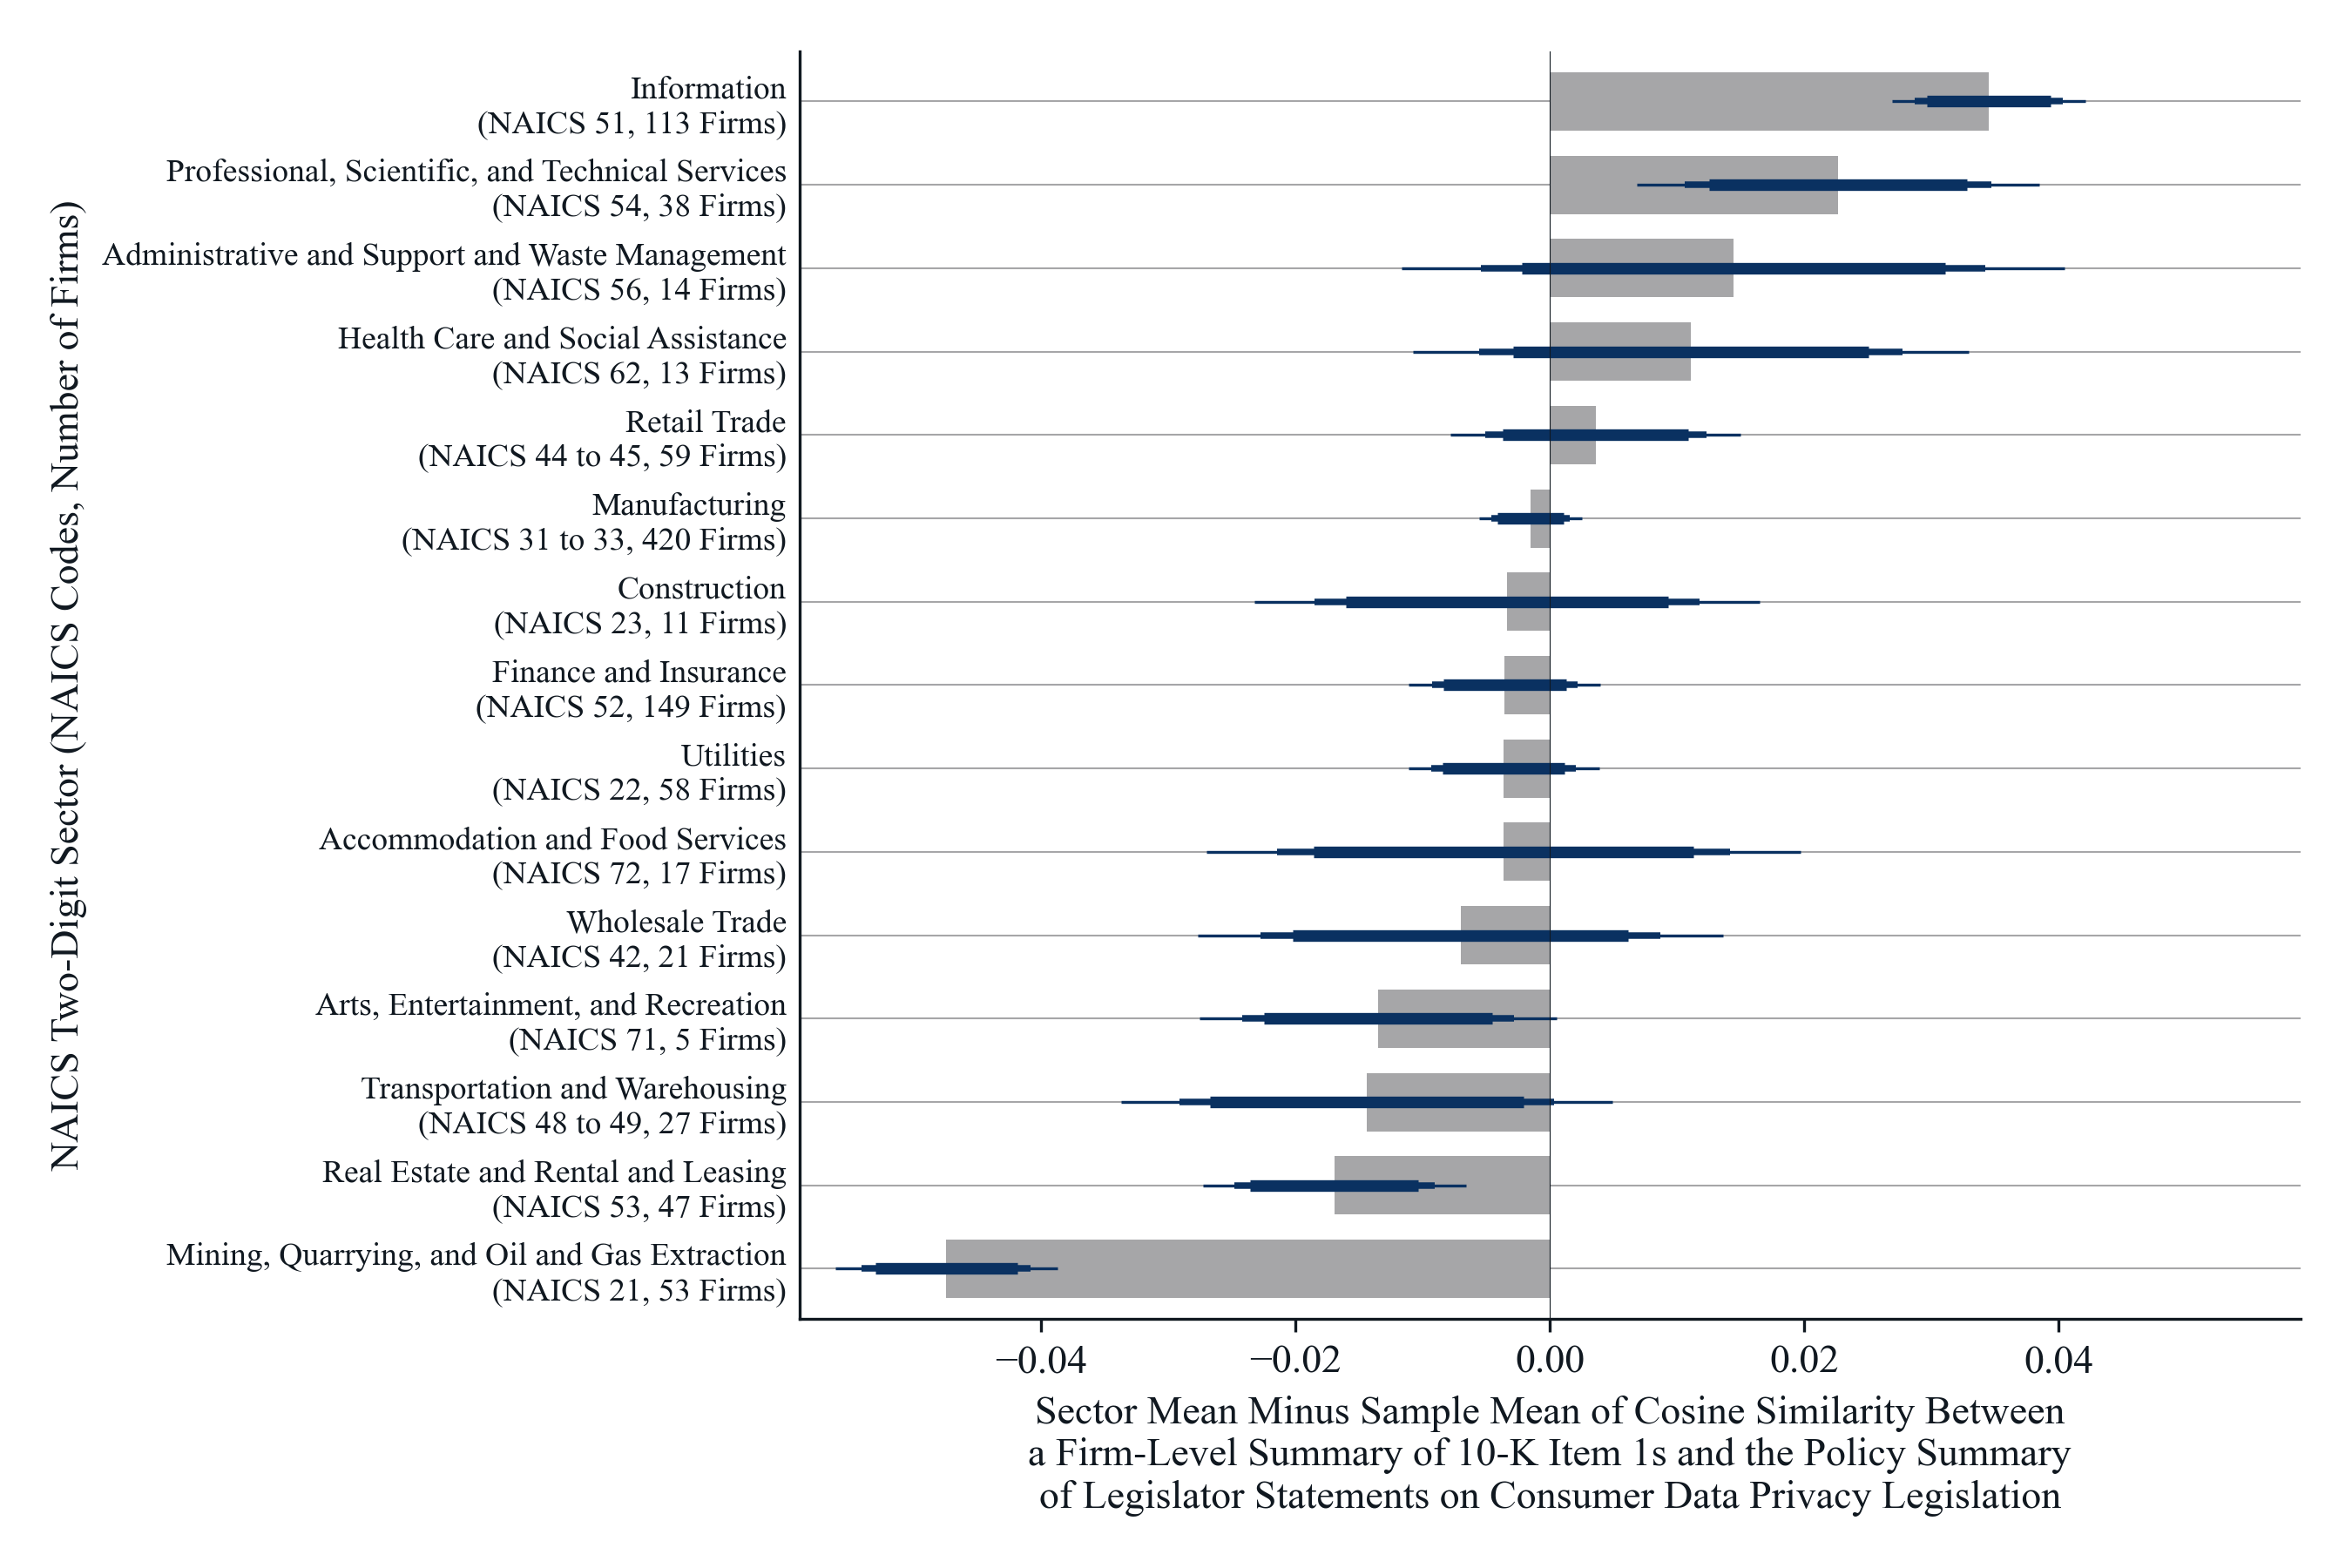

*Notes*: Each bar is the sector mean minus the sample mean of the firm score, the mean over all 1,058 firms of the all-years sample (every fiscal year a firm filed, 1999 to 2025), 0.512: zero is the sample mean, a bar to the right is a sector above it and a bar to the left a sector below it, and sectors are ordered from the highest sector mean at the top to the lowest at the bottom. The score is the cosine similarity between two embeddings: the firm-level summary, one paragraph written by the language model that condenses the firm's yearly summaries of its 10-K Item 1 (Business) sections over its fiscal years in the sample, and the policy summary, one text written by the language model that condenses the legislator statements on Topic 68, consumer data privacy legislation, extracted from congressional hearings. A higher score means that the firm's business description is closer to the policy summary. The three nested lines span the 90, 95, and 99 percent confidence intervals of the sector mean, the thickest line the 90 percent and the thinnest the 99 percent, 1.645, 1.96, and 2.576 standard errors on each side, where the standard error is the standard deviation of the firm scores within the sector divided by the square root of the number of firms; an interval that does not cross zero marks a sector whose mean differs from the sample mean at that confidence level. The sector is the firm's Compustat NAICS code cut to two digits, with codes 31 to 33 merged into manufacturing, 44 to 45 into retail trade, and 48 to 49 into transportation and warehousing; each tick label gives the codes and the number of firms. Sectors with fewer than 5 firms are left out: Unclassified (NAICS 99, 4 firms); Other Services (NAICS 81, 3 firms); Agriculture, Forestry, Fishing and Hunting (NAICS 11, 3 firms); Educational Services (NAICS 61, 3 firms).

*Source*: 10-K Item 1 sections from SEC EDGAR; congressional hearing statements from GovInfo; NAICS codes from Compustat through the CRSP-Compustat link; authors' calculations.

In [7]:
display(Markdown(f"**Figure 1. {FIGURE_TITLE}**"))
display(Image(filename=str(OUTPUT_FOLDER / f"{FIGURE_NAME}.png"), width=900))
display(Markdown(f"*Notes*: {notes}"))
display(Markdown(f"*Source*: {SOURCE}."))
